
# Module 9 — Nodes and Edges, Take Two: Bayesian Networks

**Objective (from the syllabus):** Use visual flowcharts (Bayesian Networks) to track
how evidence in one variable changes the probability of another.

**Activity 9:** Build a simple probabilistic belief network to calculate risks based
on incoming clues.

---

### Where this fits

Module 5 gave you graphs made of **hard rules**: if A, then B, full stop. Module 6
gave you graphs made of **distances and connections** — the Laplacian, the Fiedler
vector, "how far apart are these two nodes." This module gives you a third kind of
graph, and it's the one most of the real world actually runs on:

> **A graph where edges mean "this directly influences that," and the influence
> is a probability, not a certainty.**

That's a **Bayesian network**. The nodes are the same kind of thing you've been
drawing all semester — circles connected by lines. What's new is that every edge
now carries a number: *given the cause, how likely is the effect?* And once you
have those numbers, you can do something genuinely useful: watch a belief update,
in real time, as new evidence comes in.

This is also a direct cousin of the correlation-graph work from earlier in the
course. A correlation graph draws an edge when two variables move together. A
Bayesian network is more disciplined about it — it only draws an edge when one
variable **directly** causes or influences another, and it gives you the exact
mechanism (the probability table) for *how much*.



## Part 0 — Setup

We'll use **pgmpy**, the standard Python library for Bayesian networks. It gives
us:

- `DiscreteBayesianNetwork` — define the graph structure (who influences whom)
- `TabularCPD` — define the actual probability tables on each node
- `VariableElimination` — the engine that answers "given this evidence, what's
  the probability of that?"

Run the install cell below first.


In [1]:
%pip install -q pgmpy

Note: you may need to restart the kernel to use updated packages.


In [2]:

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

pd.set_option("display.width", 120)
plt.rcParams["figure.facecolor"] = "white"

print("Libraries loaded.")


/home/claude/m9venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/claude/m9venv/lib/python3.13/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Libraries loaded.



## Part 1 — The scenario: flagging a suspicious insurance claim

An insurance company wants a quick, explainable way to flag claims worth a
closer look. Nobody wants a black box here -- an investigator needs to be able
to see *why* a claim got flagged. That makes this a natural fit for a Bayesian
network: every arrow is a plain-English "this affects that," and every number
is readable on its own.

Five variables, each with two possible states:

| Node | States | What it means |
|---|---|---|
| `PriorClaims` | Yes / No | This claimant has filed multiple claims before |
| `SuspiciousTiming` | Yes / No | The claim was filed right after the policy started |
| `FraudRisk` | High / Low | **The thing we actually care about** -- hidden, not directly observed |
| `MismatchedReceipts` | Yes / No | The claimed receipts don't match the claimed items |
| `WitnessInconsistency` | Yes / No | Witness statements disagree with each other |

The structure:

- `PriorClaims` and `SuspiciousTiming` are **causes** -- things known about the
  claimant and the claim *before* anyone investigates.
- `FraudRisk` is the **hidden belief** we're trying to estimate. We never observe
  it directly; we only ever infer it.
- `MismatchedReceipts` and `WitnessInconsistency` are **clues** -- things an
  investigator discovers *after* digging into the claim, which are more likely
  to show up when fraud risk is genuinely high.

This shape -- two causes feeding a hidden risk, which in turn produces two
observable clues -- is one of the most common patterns in real Bayesian
networks (medical diagnosis, credit risk, spam filtering all use the same
skeleton).


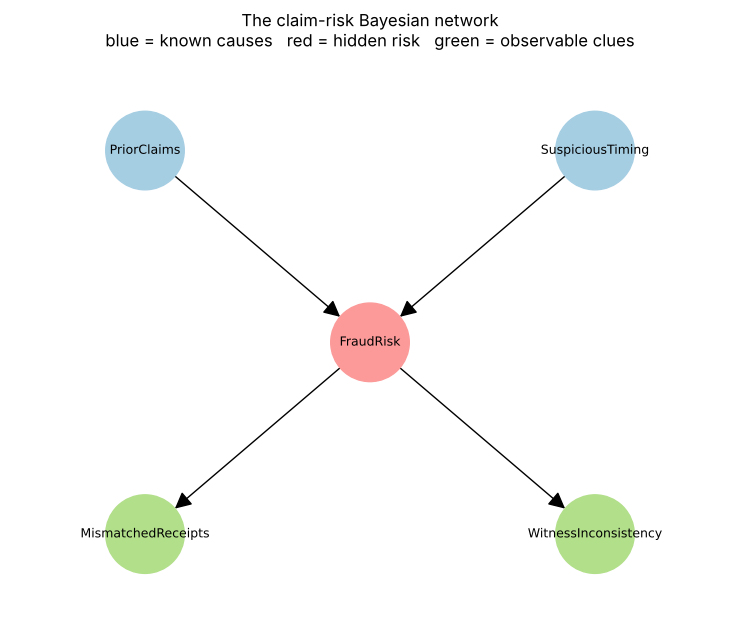

In [3]:

# the DAG structure -- who influences whom (no probabilities yet, just edges)
edges = [
    ("PriorClaims", "FraudRisk"),
    ("SuspiciousTiming", "FraudRisk"),
    ("FraudRisk", "MismatchedReceipts"),
    ("FraudRisk", "WitnessInconsistency"),
]

G = nx.DiGraph(edges)

pos = {
    "PriorClaims": (-1, 1),
    "SuspiciousTiming": (1, 1),
    "FraudRisk": (0, 0),
    "MismatchedReceipts": (-1, -1),
    "WitnessInconsistency": (1, -1),
}

color_by_node = {
    "PriorClaims": "#a6cee3",
    "SuspiciousTiming": "#a6cee3",
    "FraudRisk": "#fb9a99",
    "MismatchedReceipts": "#b2df8a",
    "WitnessInconsistency": "#b2df8a",
}
# build the color list in G's own node order -- NEVER assume it matches the
# order nodes were typed in a dict or list above; a DiGraph built from an
# edge list orders nodes by first appearance across edges, which is easy
# to get subtly wrong (we did, the first time we wrote this cell)
node_colors = [color_by_node[n] for n in G.nodes()]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
nx.draw_networkx_nodes(G, pos, node_size=3200, node_color=node_colors, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
nx.draw_networkx_edges(G, pos, arrowsize=25, arrowstyle="-|>", node_size=3200,
                        connectionstyle="arc3,rad=0.0", ax=ax)
ax.set_title("The claim-risk Bayesian network\nblue = known causes   red = hidden risk   green = observable clues")
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.5, 1.5)
ax.axis("off")
plt.tight_layout()
plt.show()



## Part 2 — Conditional Probability Tables (CPTs)

Every edge in the graph above needs a number attached to it. A **Conditional
Probability Table** (CPT) says, for every possible combination of a node's
causes, how likely each of that node's own states is.

The two root nodes (`PriorClaims`, `SuspiciousTiming`) have no causes, so their
CPTs are just plain priors -- base rates in the overall claimant population.

The three downstream nodes each have a full table: one row of probabilities
for every combination of their parents' states.

**A word of warning before we build this**: `pgmpy` expects the columns of a
CPT to follow a very specific order based on how you list the `evidence=`
variables. Get that order wrong and the model still runs -- no error, no
warning -- it just quietly computes the wrong thing. We'll come back to this
exact failure mode in Part 7, because it's a textbook "quiet bug": code that
executes cleanly and still lies to you.


In [4]:

# --- Root nodes: plain priors, no causes ---
cpd_prior = TabularCPD(
    "PriorClaims", 2, [[0.15], [0.85]],
    state_names={"PriorClaims": ["Yes", "No"]},
)

cpd_timing = TabularCPD(
    "SuspiciousTiming", 2, [[0.10], [0.90]],
    state_names={"SuspiciousTiming": ["Yes", "No"]},
)

# --- FraudRisk: depends on both PriorClaims and SuspiciousTiming ---
# Column order follows evidence=["PriorClaims", "SuspiciousTiming"]:
#   (PC=Yes,ST=Yes), (PC=Yes,ST=No), (PC=No,ST=Yes), (PC=No,ST=No)
cpd_fraud = TabularCPD(
    "FraudRisk", 2,
    [[0.90, 0.55, 0.50, 0.03],   # P(FraudRisk = High | ...)
     [0.10, 0.45, 0.50, 0.97]],  # P(FraudRisk = Low  | ...)
    evidence=["PriorClaims", "SuspiciousTiming"],
    evidence_card=[2, 2],
    state_names={
        "FraudRisk": ["High", "Low"],
        "PriorClaims": ["Yes", "No"],
        "SuspiciousTiming": ["Yes", "No"],
    },
)

# --- The two clues: each depends only on FraudRisk ---
cpd_receipts = TabularCPD(
    "MismatchedReceipts", 2,
    [[0.75, 0.05],
     [0.25, 0.95]],
    evidence=["FraudRisk"], evidence_card=[2],
    state_names={"MismatchedReceipts": ["Yes", "No"], "FraudRisk": ["High", "Low"]},
)

cpd_witness = TabularCPD(
    "WitnessInconsistency", 2,
    [[0.65, 0.04],
     [0.35, 0.96]],
    evidence=["FraudRisk"], evidence_card=[2],
    state_names={"WitnessInconsistency": ["Yes", "No"], "FraudRisk": ["High", "Low"]},
)

import itertools

def cpd_to_dataframe(cpd):
    # Readable view of a TabularCPD as a pandas DataFrame.
    #
    # Deliberately reads cpd.variables (the CPD's own internal axis order)
    # and cpd.values directly, rather than cpd.get_evidence() -- that method
    # returns the evidence list in REVERSED order from how it was passed to
    # the constructor, which would silently mislabel a DataFrame built from
    # it. This is exactly the kind of quiet mismatch Part 7 is about.
    var = cpd.variable
    var_states = cpd.state_names[var]
    evidence_vars = cpd.variables[1:]
    evidence_states = [cpd.state_names[e] for e in evidence_vars]

    rows = []
    for idx in itertools.product(*[range(len(s)) for s in evidence_states]):
        row = {ev: states[i] for ev, states, i in zip(evidence_vars, evidence_states, idx)}
        for vi, vs in enumerate(var_states):
            row[f"{var}={vs}"] = cpd.values[(vi,) + idx]
        rows.append(row)
    return pd.DataFrame(rows)

print("FraudRisk's CPT, read as a table:\n")
display(cpd_to_dataframe(cpd_fraud))


FraudRisk's CPT, read as a table:



,PriorClaims,SuspiciousTiming,FraudRisk=High,FraudRisk=Low
0,Yes,Yes,0.90,0.10
1,Yes,No,0.55,0.45
2,No,Yes,0.50,0.50
3,No,No,0.03,0.97


In [5]:

model = DiscreteBayesianNetwork(edges)
model.add_cpds(cpd_prior, cpd_timing, cpd_fraud, cpd_receipts, cpd_witness)

# check_model() verifies the graph has no cycles, every node has a CPT, and
# every CPT's columns sum to 1. It does NOT check that the columns are in
# the order you meant them to be -- keep that in mind for Part 7.
print("Model structurally valid:", model.check_model())


Model structurally valid: True



## Part 3 — Before any clues: the baseline risk

With the model built, we can ask it questions. `VariableElimination` is the
inference engine -- give it a model, it answers probability queries by
exact computation (not simulation).

First question: with **no evidence at all** -- just the base rates of
`PriorClaims` and `SuspiciousTiming` in the population -- what's the
probability that a random claim is high fraud risk?


In [6]:

infer = VariableElimination(model)

baseline = infer.query(["FraudRisk"], show_progress=False)
baseline_probs = dict(zip(baseline.state_names["FraudRisk"], baseline.values))

print("P(FraudRisk) with no evidence:")
for state, p in baseline_probs.items():
    print(f"  {state}: {p:.4f}")


P(FraudRisk) with no evidence:
  High: 0.1532
  Low: 0.8468


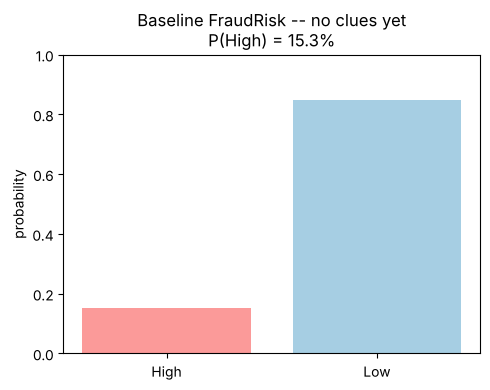

In [7]:

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["High", "Low"], [baseline_probs["High"], baseline_probs["Low"]],
       color=["#fb9a99", "#a6cee3"])
ax.set_ylim(0, 1)
ax.set_ylabel("probability")
ax.set_title(f"Baseline FraudRisk -- no clues yet\nP(High) = {baseline_probs['High']:.1%}")
plt.tight_layout()
plt.show()



That number -- call it roughly **15%** -- is just the overall base rate in the
claimant population. It's what you'd believe about *any* claim before an
investigator has looked at a single receipt. Now let's see what happens as
real evidence starts coming in.



## Part 4 — Evidence propagation: watching belief update as clues arrive

This is the heart of Activity 9: **calculate risk based on incoming clues.**

An investigator opens the file. First thing they notice: the receipts don't
match. Then they interview witnesses, and the stories don't line up either.
We'll feed each clue into the network one at a time and watch
`P(FraudRisk = High)` move.


In [8]:

# Step 1: no evidence (repeated from Part 3, for the comparison)
step0 = baseline_probs["High"]

# Step 2: receipts don't match
q1 = infer.query(["FraudRisk"], evidence={"MismatchedReceipts": "Yes"}, show_progress=False)
step1 = dict(zip(q1.state_names["FraudRisk"], q1.values))["High"]

# Step 3: witnesses disagree too
q2 = infer.query(
    ["FraudRisk"],
    evidence={"MismatchedReceipts": "Yes", "WitnessInconsistency": "Yes"},
    show_progress=False,
)
step2 = dict(zip(q2.state_names["FraudRisk"], q2.values))["High"]

print("P(FraudRisk = High) as clues accumulate:")
print(f"  no clues yet:                              {step0:.4f}")
print(f"  + mismatched receipts:                     {step1:.4f}")
print(f"  + mismatched receipts + witness conflicts:  {step2:.4f}")


P(FraudRisk = High) as clues accumulate:
  no clues yet:                              0.1532
  + mismatched receipts:                     0.7307
  + mismatched receipts + witness conflicts:  0.9778


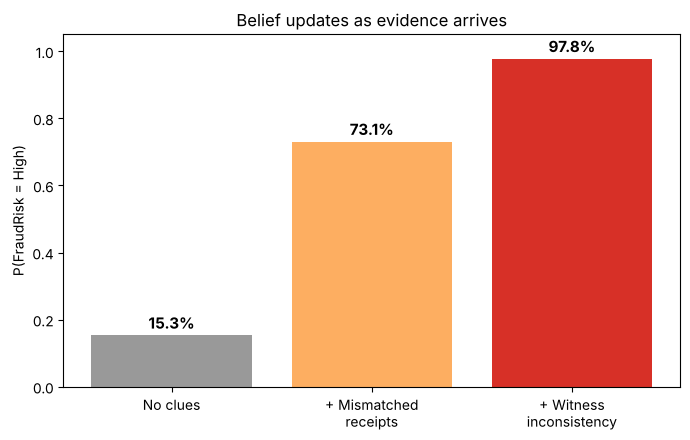

In [9]:

fig, ax = plt.subplots(figsize=(7, 4.5))
stages = ["No clues", "+ Mismatched\nreceipts", "+ Witness\ninconsistency"]
values = [step0, step1, step2]

bars = ax.bar(stages, values, color=["#999999", "#fdae61", "#d73027"])
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f"{v:.1%}",
            ha="center", fontsize=11, fontweight="bold")

ax.set_ylim(0, 1.05)
ax.set_ylabel("P(FraudRisk = High)")
ax.set_title("Belief updates as evidence arrives")
plt.tight_layout()
plt.show()



This is exactly what the network is *for*. Nothing about the underlying facts
changed -- we didn't alter the claimant, the policy, or the claim. What
changed is **what we know**, and the network tells us, precisely, how much
each new fact should move our belief. That jump from roughly 15% to roughly
73% to roughly 98% is the network doing real work: each clue is individually
more common when `FraudRisk` is high, so each one pulls the belief further in
that direction.

Notice also that this is **not** addition. Going from 73% to 98% is a much
smaller numeric jump than going from 15% to 73%, even though both are "one
more piece of evidence." Probabilities compound multiplicatively, not
additively -- which is exactly why you need a real inference engine here
instead of eyeballing it.



## Part 5 — d-separation: reading independence straight off the picture

Here's a question the graph itself can answer, before you compute a single
number: **are `MismatchedReceipts` and `WitnessInconsistency` related to each
other?**

Looking at the diagram from Part 1, neither clue points at the other -- they're
both just children of `FraudRisk`. That shape (one cause, two effects) is
called a **fork**. The rule for a fork is:

> The two children are **dependent** on each other *unless* you already know
> the shared cause. Once you know the cause, learning about one child tells
> you nothing extra about the other.

This rule -- which variables become independent once certain others are known
-- is called **d-separation** ("d" for "directional"). `pgmpy` can check it
directly, and we can verify the rule against real numbers.


In [10]:

print("Without knowing FraudRisk, are the two clues d-connected (dependent)?")
print(" ", model.is_dconnected("MismatchedReceipts", "WitnessInconsistency"))

print()
print("Once FraudRisk is known, are they still d-connected?")
print(" ", model.is_dconnected("MismatchedReceipts", "WitnessInconsistency", observed=["FraudRisk"]))


Without knowing FraudRisk, are the two clues d-connected (dependent)?
  True

Once FraudRisk is known, are they still d-connected?
  False


In [11]:

# Verify this against real numbers, not just the structural claim:
# does learning MismatchedReceipts change our belief about WitnessInconsistency,
# once FraudRisk is already pinned down?

q_a = infer.query(["WitnessInconsistency"], evidence={"FraudRisk": "High"}, show_progress=False)
q_b = infer.query(
    ["WitnessInconsistency"],
    evidence={"FraudRisk": "High", "MismatchedReceipts": "Yes"},
    show_progress=False,
)

p_a = dict(zip(q_a.state_names["WitnessInconsistency"], q_a.values))["Yes"]
p_b = dict(zip(q_b.state_names["WitnessInconsistency"], q_b.values))["Yes"]

print(f"P(WitnessInconsistency=Yes | FraudRisk=High)                          = {p_a:.4f}")
print(f"P(WitnessInconsistency=Yes | FraudRisk=High, MismatchedReceipts=Yes)  = {p_b:.4f}")
print()
print("Identical to four decimal places -- once FraudRisk is known, learning")
print("about the receipts adds nothing to what we believe about the witnesses.")
print("That's d-separation, confirmed by the actual arithmetic, not just the rule.")


P(WitnessInconsistency=Yes | FraudRisk=High)                          = 0.6500
P(WitnessInconsistency=Yes | FraudRisk=High, MismatchedReceipts=Yes)  = 0.6500

Identical to four decimal places -- once FraudRisk is known, learning
about the receipts adds nothing to what we believe about the witnesses.
That's d-separation, confirmed by the actual arithmetic, not just the rule.



Now the opposite case. `PriorClaims` and `SuspiciousTiming` both point *into*
`FraudRisk` -- that shape (two causes, one shared effect) is called a
**collider**, and the rule for a collider is the mirror image of the fork
rule:

> Two causes of a shared effect are **independent** of each other --
> *until* you observe the effect. Observing the effect "opens a path"
> between the two causes.

This is the strange one: observing a *downstream* fact can create a
dependency between two things that otherwise have nothing to do with each
other.


In [12]:

print("Without any evidence, are PriorClaims and SuspiciousTiming d-connected?")
print(" ", model.is_dconnected("PriorClaims", "SuspiciousTiming"))

print()
print("Once FraudRisk is observed, are they d-connected?")
print(" ", model.is_dconnected("PriorClaims", "SuspiciousTiming", observed=["FraudRisk"]))


Without any evidence, are PriorClaims and SuspiciousTiming d-connected?
  False

Once FraudRisk is observed, are they d-connected?
  True



They start independent, and observing `FraudRisk` makes them dependent. That
might look like a typo, but it's one of the genuinely useful, slightly
counterintuitive facts a Bayesian network gives you -- and it sets up the next
section perfectly.



## Part 6 — "Explaining away": when one clue makes another less suspicious

This is the collider pattern from Part 5, made concrete.

Suppose a claim is flagged as high fraud risk. Naturally, that raises
suspicion about *both* possible causes: maybe the claimant has a history of
prior claims, maybe the timing was suspicious, or maybe both.

Now suppose an investigator discovers that yes, this claimant has multiple
prior claims. Does that make the suspicious timing *more* suspicious, *less*
suspicious, or does nothing change?

Intuition says: once you have one good explanation for why the risk is high,
the *other* possible explanation gets a little less necessary. The claim's
riskiness is already "explained" by the prior-claims history -- there's less
left over that needs explaining by the timing. This is called **explaining
away**, and it's a real, provable consequence of the collider structure.


In [13]:

q_before = infer.query(["SuspiciousTiming"], evidence={"FraudRisk": "High"}, show_progress=False)
p_before = dict(zip(q_before.state_names["SuspiciousTiming"], q_before.values))["Yes"]

q_after = infer.query(
    ["SuspiciousTiming"],
    evidence={"FraudRisk": "High", "PriorClaims": "Yes"},
    show_progress=False,
)
p_after = dict(zip(q_after.state_names["SuspiciousTiming"], q_after.values))["Yes"]

print(f"P(SuspiciousTiming=Yes | FraudRisk=High)                     = {p_before:.4f}")
print(f"P(SuspiciousTiming=Yes | FraudRisk=High, PriorClaims=Yes)    = {p_after:.4f}")
print(f"\nChange: {p_after - p_before:+.4f}  -- belief in suspicious timing went DOWN")
print("once prior claims history already explained the high risk.")


P(SuspiciousTiming=Yes | FraudRisk=High)                     = 0.3655
P(SuspiciousTiming=Yes | FraudRisk=High, PriorClaims=Yes)    = 0.1538

Change: -0.2117  -- belief in suspicious timing went DOWN
once prior claims history already explained the high risk.


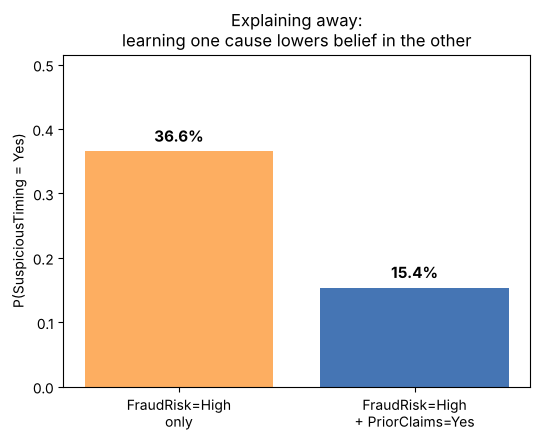

In [14]:

fig, ax = plt.subplots(figsize=(5.5, 4.5))
bars = ax.bar(
    ["FraudRisk=High\nonly", "FraudRisk=High\n+ PriorClaims=Yes"],
    [p_before, p_after],
    color=["#fdae61", "#4575b4"],
)
for bar, v in zip(bars, [p_before, p_after]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f"{v:.1%}",
            ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, max(p_before, p_after) + 0.15)
ax.set_ylabel("P(SuspiciousTiming = Yes)")
ax.set_title("Explaining away:\nlearning one cause lowers belief in the other")
plt.tight_layout()
plt.show()



Nothing about the actual timing of the claim changed. What changed is that
one explanation for the high risk became confirmed, which makes the
*other* explanation less necessary to believe in. This is exactly why
medical diagnosis systems, fraud systems, and troubleshooting checklists all
lean on this same structure -- confirming one plausible cause genuinely
should lower your suspicion of a competing one, and a Bayesian network gives
you the actual number instead of a gut feeling.



## Part 7 — Quiet bug: when the column order is silently wrong

Back in Part 2, there was a warning: `pgmpy` expects the columns of a CPT to
follow the order implied by `evidence=[...]`, and if you get it wrong, the
model **does not complain**. It builds fine. `check_model()` still returns
`True`. It just answers questions incorrectly from then on.

Let's reproduce that exact mistake on purpose. We'll rebuild `FraudRisk`'s
CPT with the evidence list order swapped -- `["SuspiciousTiming",
"PriorClaims"]` instead of `["PriorClaims", "SuspiciousTiming"]` -- while
copy-pasting the *same* column values. This is a completely realistic typo:
it's the kind of thing that happens when you reorder two lines of code and
forget the table underneath has to match.


In [15]:

# the CORRECT version (same as Part 2, rebuilt here for a side-by-side comparison)
cpd_fraud_correct = TabularCPD(
    "FraudRisk", 2,
    [[0.90, 0.55, 0.50, 0.03],
     [0.10, 0.45, 0.50, 0.97]],
    evidence=["PriorClaims", "SuspiciousTiming"], evidence_card=[2, 2],
    state_names={"FraudRisk": ["High", "Low"], "PriorClaims": ["Yes", "No"],
                 "SuspiciousTiming": ["Yes", "No"]},
)

# the BUGGY version -- evidence order swapped, column values left untouched
cpd_fraud_buggy = TabularCPD(
    "FraudRisk", 2,
    [[0.90, 0.55, 0.50, 0.03],
     [0.10, 0.45, 0.50, 0.97]],
    evidence=["SuspiciousTiming", "PriorClaims"], evidence_card=[2, 2],   # <-- swapped!
    state_names={"FraudRisk": ["High", "Low"], "PriorClaims": ["Yes", "No"],
                 "SuspiciousTiming": ["Yes", "No"]},
)

def build_model(fraud_cpd):
    m = DiscreteBayesianNetwork([("PriorClaims", "FraudRisk"), ("SuspiciousTiming", "FraudRisk")])
    m.add_cpds(cpd_prior, cpd_timing, fraud_cpd)
    return m

model_correct = build_model(cpd_fraud_correct)
model_buggy = build_model(cpd_fraud_buggy)

print("Correct model check_model():", model_correct.check_model())
print("Buggy model   check_model():", model_buggy.check_model())
print()
print("Both say True. Nothing here catches the mistake.")


Correct model check_model(): True
Buggy model   check_model(): True

Both say True. Nothing here catches the mistake.


In [16]:

infer_correct = VariableElimination(model_correct)
infer_buggy = VariableElimination(model_buggy)

print(f"{'evidence':<45}{'correct P(High)':>18}{'buggy P(High)':>18}")
for pc, st in [("Yes", "No"), ("No", "Yes")]:
    qc = infer_correct.query(["FraudRisk"], evidence={"PriorClaims": pc, "SuspiciousTiming": st}, show_progress=False)
    qb = infer_buggy.query(["FraudRisk"], evidence={"PriorClaims": pc, "SuspiciousTiming": st}, show_progress=False)
    pc_val = dict(zip(qc.state_names["FraudRisk"], qc.values))["High"]
    pb_val = dict(zip(qb.state_names["FraudRisk"], qb.values))["High"]
    label = f"PriorClaims={pc}, SuspiciousTiming={st}"
    print(f"{label:<45}{pc_val:>18.3f}{pb_val:>18.3f}")


evidence                                        correct P(High)     buggy P(High)
PriorClaims=Yes, SuspiciousTiming=No                      0.550             0.500
PriorClaims=No, SuspiciousTiming=Yes                      0.500             0.550



Look closely: the two rows' numbers are simply **swapped** between the
correct and buggy versions. `PriorClaims=Yes, SuspiciousTiming=No` should
give 0.55 -- the buggy model instead gives it 0.50, which was meant for the
*other* combination. The buggy model isn't obviously broken. It still
produces valid-looking probabilities between 0 and 1. It still runs every
query without an error. An investigator using the buggy version would
systematically mis-rank which claims deserve a second look, with no warning
that anything was wrong.

**The fix** is simple once you know to look for it: always keep the order of
`evidence=[...]` and the order of combinations in your column data in sync,
and double check with a query you can verify by hand -- which is exactly the
comparison we just ran.

**Working rule:** whenever a CPT (or any function with positional
arguments and a parallel data table) takes a *list* that defines column
order, write a same-input-different-order sanity check before you trust the
model's output on anything that matters.



## Part 8 — Wrap-up

What this network can do, in one sentence: it turns "I have a few new facts"
into "here's exactly how much more or less I should believe the thing I
actually care about" -- without ever needing the hidden variable to be
directly observed.

Quick recap of the five ideas:

1. **CPTs** are the actual content of a Bayesian network -- the graph alone is
   just structure; the probability tables are where the real claims live.
2. **Evidence propagation** is the main event: each new clue updates the
   belief multiplicatively, not additively, and the order clues arrive in
   doesn't change the final answer (though it can change how the story
   *feels* while you're investigating).
3. **d-separation** lets you read independence and dependence straight off
   the picture, before computing anything -- forks need their shared cause
   observed to become independent; colliders need their shared effect
   observed to become dependent.
4. **Explaining away** is the practical payoff of the collider rule: one
   confirmed cause can genuinely lower suspicion of a competing cause.
5. **Quiet bugs** are still here, same as every module this semester --
   this time hiding in column order instead of edge weights.

**Where this goes next:** Module 10 is about anomaly detection and
distribution shift -- automatically flagging when new data doesn't look like
what a model has seen before. The belief-updating machinery here is the
single-case version of that idea: this module asks "given these clues, how
risky is *this one claim*?" Next module asks the population-level question:
"has the *whole dataset* started looking different than it used to?"
